In [1]:
!pip install pandas numpy matplotlib seaborn openpyxl

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

PROJECT_PATH = "/content/drive/MyDrive/ATMIQ_HACKATHON"

DATASET_PATH = os.path.join(
    PROJECT_PATH,
    "Dataset"
)

EXCEL_PATH = os.path.join(
    DATASET_PATH,
    "bank_campaign_participant_release.xlsx"
)

print("Dataset path:", EXCEL_PATH)
print("File exists:", os.path.exists(EXCEL_PATH))

Dataset path: /content/drive/MyDrive/ATMIQ_HACKATHON/Dataset/bank_campaign_participant_release.xlsx
File exists: True


In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("My Drive folders:")
print(os.listdir('/content/drive/MyDrive'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
My Drive folders:
['Colab Notebooks', '#Feluda _ Indrojal Rahasya _ ইন্দ্রজাল রহস্য। ফেলুদা । Satyajit Ray _ Bangla Audiobook _#Gopposhoppo [kRsrVoFGNHo].mp3', 'Byomkesh Bakshi _ Kohen Kobi Kalidas _ Bengali Audio Story _ Sunday Suspense [F60JZp3eXck].mp3', 'Detective Byomkesh Bakshi _ Khuji Khuji Nari _ Sharadindu Bandopadhyay _ খুঁজি খুঁজি নারি ব্যোমকেশ [K3zp6Xba8PA].mp3', 'Samagra Tathya Presents - Dusto Chakra _ দুষ্ট চক্র _ Byomkesh Bakshi _ Full Audio Story _ [cNga8sTzX4M].mp3', 'Info for BTech 1st year students', 'Classroom', 'IKS Review Article_ Pratanu Bhattacharyya 85_Aditya Ghosh 84_Ayanita Goswami72.pdf', 'Avionix Group- Yveltal.pptx', 'Pratanu', 'IFF_Quantum_Circuits.ipynb', 'ATMIQ_HACKATHON']


In [5]:
import os

search_folder = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_folder):
    for file in files:
        if file == "bank_campaign_participant_release.xlsx":
            print("EXACT FILE PATH:")
            print(os.path.join(root, file))

EXACT FILE PATH:
/content/drive/MyDrive/ATMIQ_HACKATHON/Dataset/bank_campaign_participant_release.xlsx


In [6]:
import pandas as pd
import numpy as np

excel_file = pd.ExcelFile(EXCEL_PATH)

print("Excel workbook loaded successfully!")

print("\nAvailable sheets:")

for sheet in excel_file.sheet_names:
    print("-", sheet)

Excel workbook loaded successfully!

Available sheets:
- README
- Stage1_Train
- Stage1_Test
- Stage2_Data
- Stage2_Constraints


In [7]:
readme = pd.read_excel(EXCEL_PATH, sheet_name="README")

train_df = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Stage1_Train"
)

test_df = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Stage1_Test"
)

stage2_df = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Stage2_Data"
)

constraints_df = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Stage2_Constraints"
)

print("All sheets loaded successfully!")

All sheets loaded successfully!


In [8]:
datasets = {
    "Stage1_Train": train_df,
    "Stage1_Test": test_df,
    "Stage2_Data": stage2_df,
    "Stage2_Constraints": constraints_df,
    "README": readme
}

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Rows:", df.shape[0])

    print("Columns:", df.shape[1])

    print("Shape:", df.shape)


Dataset: Stage1_Train
Rows: 300
Columns: 17
Shape: (300, 17)

Dataset: Stage1_Test
Rows: 100
Columns: 15
Shape: (100, 15)

Dataset: Stage2_Data
Rows: 400
Columns: 5
Shape: (400, 5)

Dataset: Stage2_Constraints
Rows: 6
Columns: 4
Shape: (6, 4)

Dataset: README
Rows: 20
Columns: 2
Shape: (20, 2)


In [9]:
print("TRAINING DATASET COLUMNS")

for i, column in enumerate(train_df.columns, start=1):

    print(i, ":", column)

TRAINING DATASET COLUMNS
1 : customer_id
2 : age
3 : job
4 : marital
5 : education
6 : default
7 : balance
8 : housing
9 : loan
10 : contact
11 : day
12 : month
13 : campaign
14 : pdays
15 : previous
16 : poutcome
17 : y


In [10]:
print("TRAINING DATA")

display(train_df.head())

print("TEST DATA")

display(test_df.head())

print("STAGE 2 DATA")

display(stage2_df.head())

TRAINING DATA


,customer_id,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,C0273,51,technician,married,primary,no,1550,no,no,unknown,20,jun,5,-1,0,unknown,no
1,C0353,51,self-employed,married,secondary,yes,34,no,yes,cellular,7,jul,1,-1,0,unknown,no
2,C0201,32,services,married,tertiary,no,4908,no,yes,cellular,13,may,2,-1,0,unknown,no
3,C0014,43,blue-collar,married,secondary,no,10910,yes,no,cellular,15,may,2,-1,0,unknown,no
4,C0308,37,management,married,tertiary,no,5355,no,no,telephone,17,feb,4,-1,0,unknown,yes


TEST DATA


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
0,40,management,married,tertiary,no,194,no,yes,cellular,29,aug,2,-1,0,unknown
1,59,retired,married,secondary,no,5706,yes,no,cellular,25,jul,2,-1,0,unknown
2,36,management,single,tertiary,no,876,yes,no,unknown,23,may,2,-1,0,unknown
3,56,entrepreneur,married,unknown,no,575,no,no,unknown,20,jun,2,-1,0,unknown
4,37,management,married,tertiary,no,3288,no,no,cellular,8,aug,2,-1,0,unknown


STAGE 2 DATA


,customer_id,contact_cost,expected_deposit_value,capacity_units,customer_segment
0,C0001,1,30,1,D
1,C0002,4,26,2,B
2,C0003,3,18,3,D
3,C0004,2,30,4,D
4,C0005,2,21,3,C


In [11]:
print("TRAINING DATA TYPES")

print(train_df.dtypes)

TRAINING DATA TYPES
customer_id    object
age             int64
job            object
marital        object
education      object
default        object
balance         int64
housing        object
loan           object
contact        object
day             int64
month          object
campaign        int64
pdays           int64
previous        int64
poutcome       object
y              object
dtype: object


In [12]:
print("MISSING VALUES IN TRAINING DATA")

print(train_df.isnull().sum())

print("\nMISSING VALUES IN TEST DATA")

print(test_df.isnull().sum())

print("\nMISSING VALUES IN STAGE 2 DATA")

print(stage2_df.isnull().sum())

MISSING VALUES IN TRAINING DATA
customer_id    0
age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64

MISSING VALUES IN TEST DATA
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
campaign     0
pdays        0
previous     0
poutcome     0
dtype: int64

MISSING VALUES IN STAGE 2 DATA
customer_id               0
contact_cost              0
expected_deposit_value    0
capacity_units            0
customer_segment          0
dtype: int64


In [13]:
print("Training duplicates:",
      train_df.duplicated().sum())

print("Test duplicates:",
      test_df.duplicated().sum())

print("Stage 2 duplicates:",
      stage2_df.duplicated().sum())

Training duplicates: 0
Test duplicates: 0
Stage 2 duplicates: 0


In [14]:
print("Target distribution:")

print(train_df["y"].value_counts())

print("\nTarget percentage:")

print(
    train_df["y"]
    .value_counts(normalize=True) * 100
)

Target distribution:
y
no     265
yes     35
Name: count, dtype: int64

Target percentage:
y
no     88.333333
yes    11.666667
Name: proportion, dtype: float64


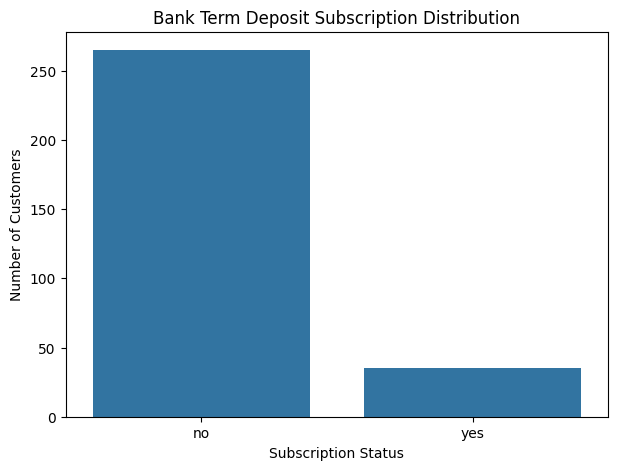

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="y"
)

plt.title("Bank Term Deposit Subscription Distribution")

plt.xlabel("Subscription Status")

plt.ylabel("Number of Customers")

plt.show()

In [16]:
print("NUMERICAL FEATURE SUMMARY")

display(train_df.describe())

NUMERICAL FEATURE SUMMARY


,age,balance,day,campaign,pdays,previous
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,40.786667,1695.953333,16.713333,2.920000,31.696667,0.436667
std,10.667418,3412.929414,8.705771,3.998361,86.844215,1.282499
min,22.000000,-2082.000000,1.000000,1.000000,-1.000000,0.000000
25%,33.000000,58.250000,9.000000,1.000000,-1.000000,0.000000
50%,39.000000,460.500000,17.000000,2.000000,-1.000000,0.000000
75%,48.000000,1588.500000,25.000000,3.000000,-1.000000,0.000000
max,80.000000,27069.000000,31.000000,50.000000,385.000000,8.000000


In [17]:
categorical_columns = train_df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:

    print("\nColumn:", column)

    print(train_df[column].value_counts())


Column: customer_id
customer_id
C0273    1
C0353    1
C0201    1
C0014    1
C0308    1
        ..
C0251    1
C0104    1
C0145    1
C0358    1
C0141    1
Name: count, Length: 300, dtype: int64

Column: job
job
management       76
blue-collar      66
technician       54
admin.           29
services         17
self-employed    13
retired          13
unemployed       12
entrepreneur     11
housemaid         6
student           2
unknown           1
Name: count, dtype: int64

Column: marital
marital
married     190
single       83
divorced     27
Name: count, dtype: int64

Column: education
education
secondary    147
tertiary     104
primary       35
unknown       14
Name: count, dtype: int64

Column: default
default
no     296
yes      4
Name: count, dtype: int64

Column: housing
housing
yes    168
no     132
Name: count, dtype: int64

Column: loan
loan
no     255
yes     45
Name: count, dtype: int64

Column: contact
contact
cellular     185
unknown       91
telephone     24
Name: count, 

In [18]:
print("OFFICIAL STAGE 2 CONSTRAINTS")

display(constraints_df)

OFFICIAL STAGE 2 CONSTRAINTS


,parameter,symbol,value,constraint / rule
0,Candidate count,N,10,Candidates = top 10 Stage1_Test customers by p...
1,Exact selection,K,6,SUM(x_i) = 6
2,Budget,C,25,SUM(contact_cost_i * x_i) <= 25
3,Capacity,H,22,SUM(capacity_units_i * x_i) <= 22
4,Decision variable,x_i,0 or 1,"x_i = contact_decision (1 = contact, 0 = do no..."
5,Objective,Z,Maximize,Z = SUM(expected_net_value_i * x_i)


In [19]:
print("STAGE 2 CUSTOMER DATA")

display(stage2_df.head(10))

print("\nSTAGE 2 COLUMN INFORMATION")

print(stage2_df.dtypes)

STAGE 2 CUSTOMER DATA


,customer_id,contact_cost,expected_deposit_value,capacity_units,customer_segment
0,C0001,1,30,1,D
1,C0002,4,26,2,B
2,C0003,3,18,3,D
3,C0004,2,30,4,D
4,C0005,2,21,3,C
5,C0006,4,21,4,D
6,C0007,1,20,3,C
7,C0008,3,14,1,C
8,C0009,1,29,2,B
9,C0010,1,12,4,D



STAGE 2 COLUMN INFORMATION
customer_id               object
contact_cost               int64
expected_deposit_value     int64
capacity_units             int64
customer_segment          object
dtype: object


In [20]:
print("DATASET VALIDATION")

print("\nTarget column exists:",
      "y" in train_df.columns)

print("Duration in training:",
      "duration" in train_df.columns)

print("Customer ID in training:",
      "customer_id" in train_df.columns)

print("Customer ID in test:",
      "customer_id" in test_df.columns)

print("Customer ID in Stage 2:",
      "customer_id" in stage2_df.columns)

print("\nTraining shape:", train_df.shape)

print("Testing shape:", test_df.shape)

print("\nTarget distribution:")

print(train_df["y"].value_counts())

DATASET VALIDATION

Target column exists: True
Duration in training: False
Customer ID in training: True
Customer ID in test: False
Customer ID in Stage 2: True

Training shape: (300, 17)
Testing shape: (100, 15)

Target distribution:
y
no     265
yes     35
Name: count, dtype: int64


In [21]:
print("README INFORMATION")

display(readme)

print("\nSTAGE 2 CUSTOMER IDs")

display(stage2_df[["customer_id"]].head(20))

README INFORMATION


,Item,Details
0,Dataset source,bank.csv
1,Total sampled customers,400
2,Stage 1 training samples,300
3,Stage 1 test samples,100
4,Stage 1 target,y = yes/no
5,Overall target distribution,46 yes\n354 no
6,Training target distribution,35 yes\n265 no
7,Removed field,duration
8,Stage 1 task,Train the subscription prediction model using ...
9,Stage 2 candidate rule,Rank the 100 Stage1_Test customers by predicte...



STAGE 2 CUSTOMER IDs


,customer_id
0,C0001
1,C0002
2,C0003
3,C0004
4,C0005
5,C0006
6,C0007
7,C0008
8,C0009
9,C0010


In [22]:
RESULTS_PATH = os.path.join(
    PROJECT_PATH,
    "Results"
)

os.makedirs(
    RESULTS_PATH,
    exist_ok=True
)

print("Results folder created successfully!")

Results folder created successfully!


In [23]:
inspection_report = []

for name, df in datasets.items():

    inspection_report.append({

        "Dataset": name,

        "Rows": df.shape[0],

        "Columns": df.shape[1],

        "Missing Values": df.isnull().sum().sum(),

        "Duplicate Rows": df.duplicated().sum()

    })

inspection_df = pd.DataFrame(inspection_report)

display(inspection_df)

inspection_df.to_csv(
    os.path.join(
        RESULTS_PATH,
        "dataset_inspection_report.csv"
    ),
    index=False
)

print("Inspection report saved successfully!")

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,Stage1_Train,300,17,0,0
1,Stage1_Test,100,15,0,0
2,Stage2_Data,400,5,0,0
3,Stage2_Constraints,6,4,0,0
4,README,20,2,0,0


Inspection report saved successfully!
